# Exp3 torus test analysis

本 notebook 自动适配 `direct_sfr` 与 `signed_closure` 两种 Exp3 训练结果。分析模式从结果目录中的 `hyperparameters.json` 和 checkpoint 读取，无需手动设置。统计量仅包含总体物理 SFR 的 RMSE、MAE、R²，以及全时间段积分 SFR 低估百分比；正百分比表示低估，负百分比表示高估。图表功能与 Exp2 测试域一致：真值-预测散点图、误差分布、SFR 时间演化和累积恒星形成质量。

In [4]:
# 只需把这里改成任意 Exp3 Direct 或 Closure 结果目录。
RESULT_DIR = (
    r'D:\research\ai+MACERsimulation\MACNet-v1\Results'
    r'\Exp3_Rh12x20_FiveRuns_Direct_Trial61Params_seed42_20260920_114307'
)
ANALYSIS_BATCH_SIZE = 256

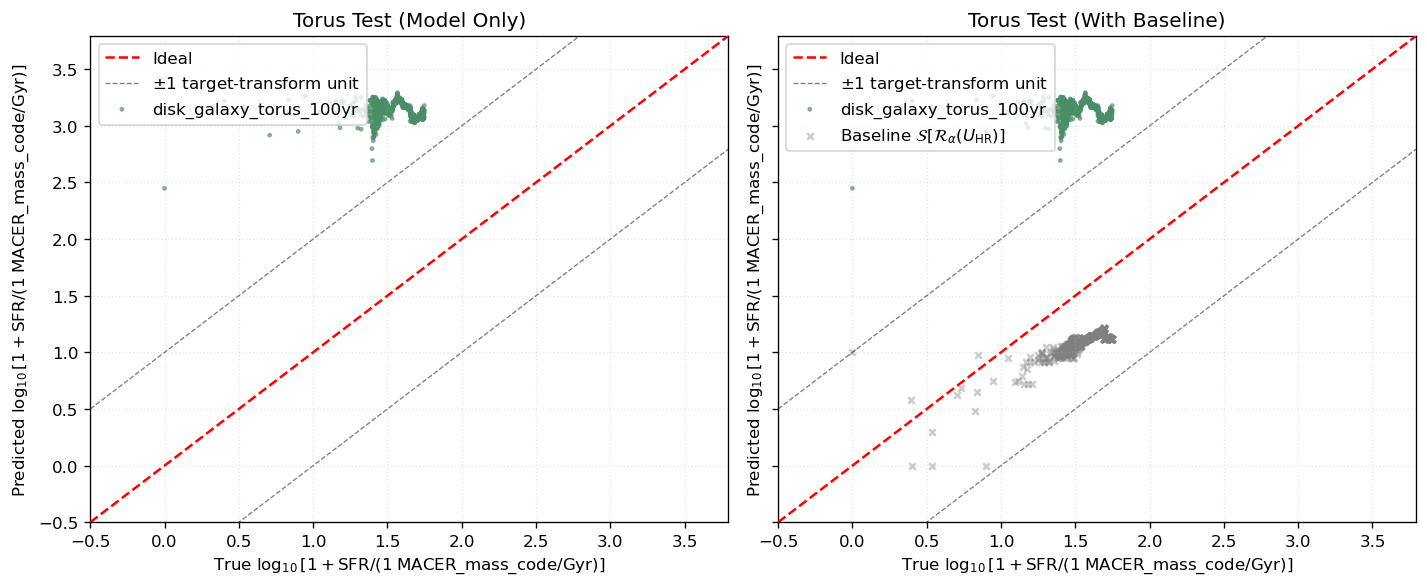

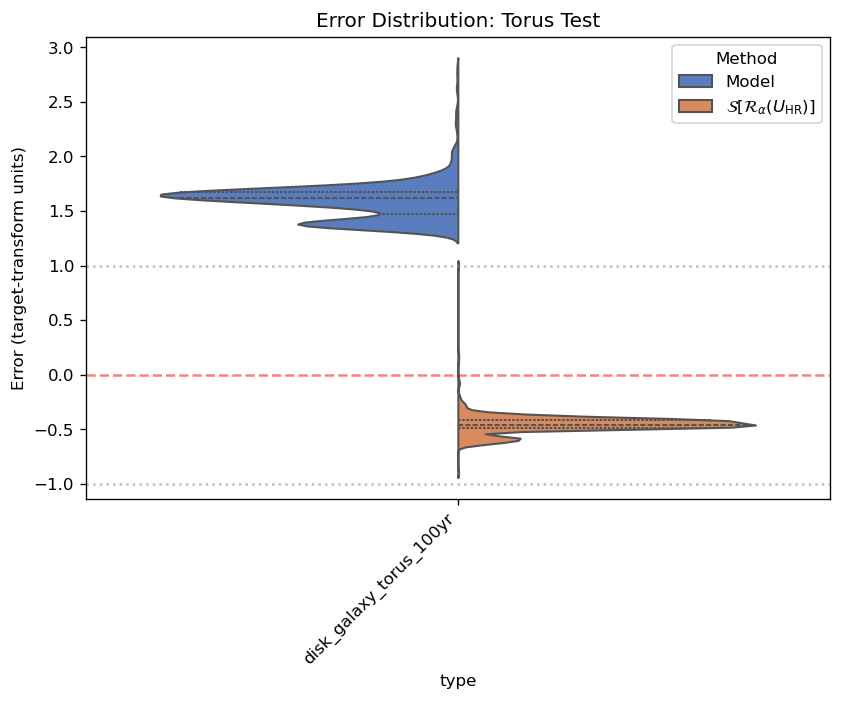

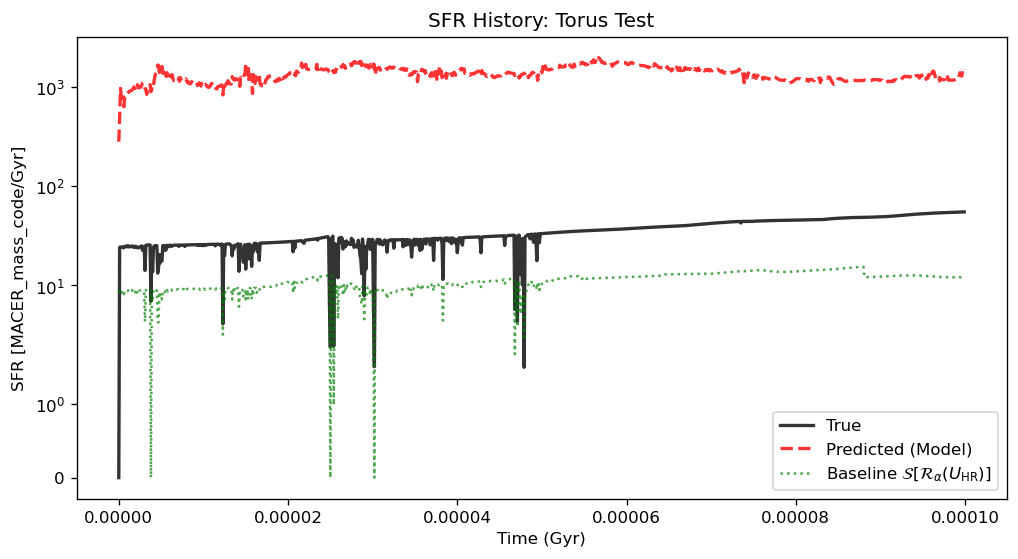

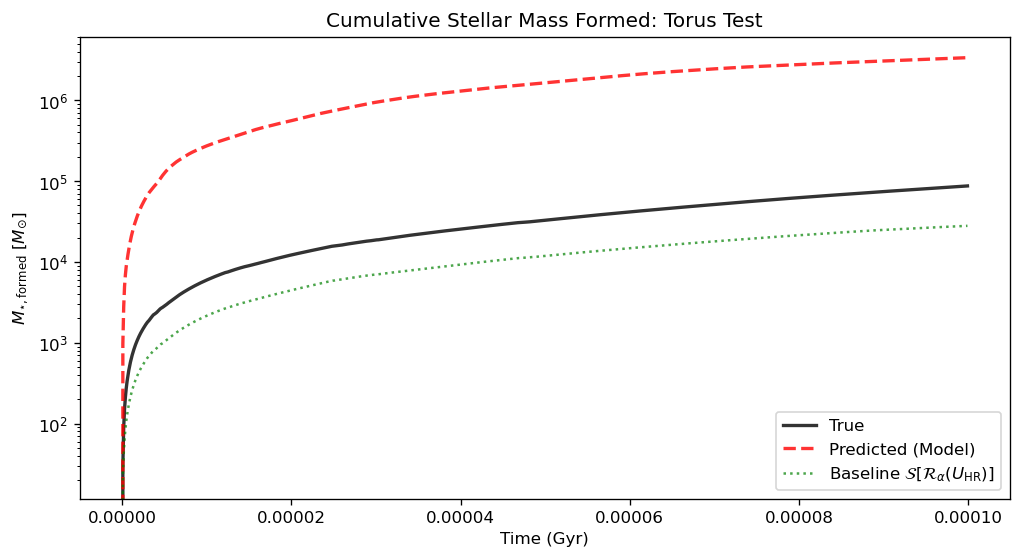

Exp3 torus predictions: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp3_Rh12x20_FiveRuns_Direct_Trial61Params_seed42_20260920_114307\torus_test_predictions.csv
Exp3 metrics: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp3_Rh12x20_FiveRuns_Direct_Trial61Params_seed42_20260920_114307\metrics_exp3.csv
Exp3 objective mode: direct_sfr
   Dataset        RMSE         MAE           R2  TotalPeriod_SFR_UnderestimatePct
Torus Test 1335.050139 1316.039035 -16552.15057                      -3763.541637


In [5]:
import importlib
import sys
from pathlib import Path

import pandas as pd
import torch
from IPython.display import display

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / 'Experiment').is_dir() and (path / '.config').is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError('Could not locate the MACNet-v1 project root.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from VisualScripts.ResultAnalysis import analysis_utils, analyze_exp3
importlib.reload(analysis_utils)
importlib.reload(analyze_exp3)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
metrics_path = analyze_exp3.analyze_result(
    Path(RESULT_DIR),
    device,
    batch_size=ANALYSIS_BATCH_SIZE,
)

In [6]:
import json

result_dir = Path(RESULT_DIR)
analysis_metadata = json.loads(
    (result_dir / 'exp3_analysis_metadata.json').read_text(encoding='utf-8')
)
print('Objective mode:', analysis_metadata['objective_mode'])
metrics = pd.read_csv(metrics_path)
display(metrics)
print('Predictions:', result_dir / 'torus_test_predictions.csv')
print('Figures:', result_dir / 'figures_exp3')

Objective mode: direct_sfr


,Dataset,RMSE,MAE,R2,TotalPeriod_SFR_UnderestimatePct
0,Torus Test,1335.050139,1316.039035,-16552.15057,-3763.541637


Predictions: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp3_Rh12x20_FiveRuns_Direct_Trial61Params_seed42_20260920_114307\torus_test_predictions.csv
Figures: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp3_Rh12x20_FiveRuns_Direct_Trial61Params_seed42_20260920_114307\figures_exp3
